IMPORTS

In [8]:
import glob
import os
import shutil
import random

import h5py
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from dataset import Dataset

PATHS

In [9]:
DATASET_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Data/ae4353-2026"

OUTPUT_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Output/model1"

In [10]:

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"There is no folder at {DATASET_PATH}.\n"
        "Copy the real path from the Input panel on the right: expand the "
        "competition data, hover over its folder, and click the copy-path icon."
    )

shutil.copy(f"{DATASET_PATH}/metric.py", "metric.py")
from metric import rle_encode, rle_decode, global_dice, write_submission

train_files = sorted(glob.glob(f"{DATASET_PATH}/train_*.h5"))
test_files = sorted(glob.glob(f"{DATASET_PATH}/test_*.h5"))
print("Paths initialized.")

Paths initialized.


SEED

In [11]:
SEED = 2006                                   # any fixed number
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)                     # seeds the GPU as well
torch.backends.cudnn.benchmark = False      # the same algorithms on every run
torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


LOADER

Found 2636 images containing contrails.


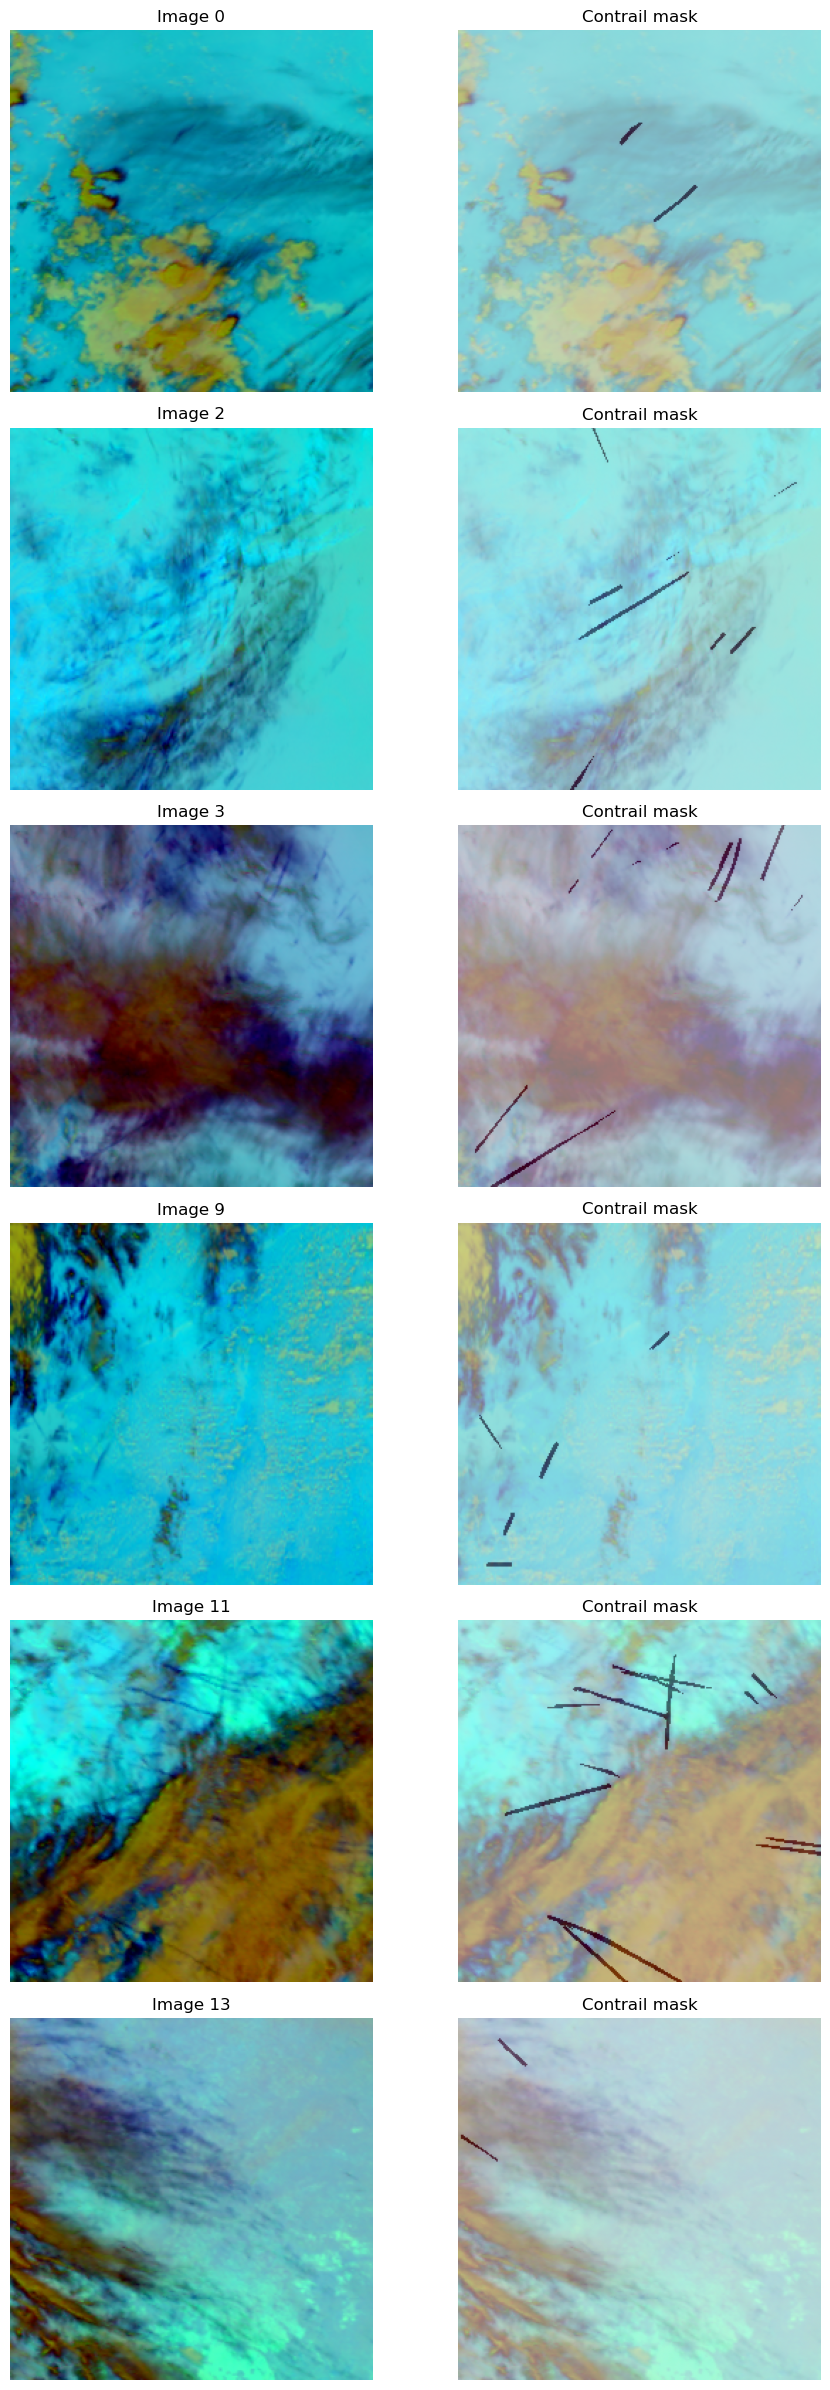

In [12]:
BATCH_SIZE = 8
NUM_WORKERS = 4


train_dataset = Dataset(train_files, is_train=True)
test_dataset = Dataset(test_files, is_train=False)

positive_indices = []

for index in range(len(dataset)):

    _, mask = dataset[index]
    if torch.any(mask > 0):
        positive_indices.append(index)

print(f"Found {len(positive_indices)} images containing contrails.")

n_to_plot = min(6, len(positive_indices))
if n_to_plot:
    fig, axes = plt.subplots(n_to_plot, 2, figsize=(10, 4 * n_to_plot))
    axes = np.atleast_2d(axes)

    for row, index in enumerate(positive_indices[:n_to_plot]):
        image, mask = dataset[index]
        image_np = image.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze(0).numpy()

        axes[row, 0].imshow(image_np)
        axes[row, 0].set_title(f"Image {index}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(image_np)
        axes[row, 1].imshow(mask_np, cmap="Reds", alpha=0.5)
        axes[row, 1].set_title("Contrail mask")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)
